# Aula 9 - Avaliação de modelos de regressão
### Regressão linear simples e múltipla, do modelo à avaliação
**Professor Daniel da Silva Souza** · Aprendizagem de Máquina

**Pergunta da aula:** se um modelo prevê 12 km/L para um carro que faz 10 km/L, como avaliamos esse resultado?

Na classificação, comparamos categorias. Na regressão, queremos saber **o quanto o valor previsto se aproxima do valor real**.

Nesta aula, vamos:
- entender as equações da regressão linear simples e múltipla;
- prever a eficiência de combustível de carros usando uma base real;
- calcular e interpretar MAE, MSE, RMSE e $R^2$;
- visualizar a reta, o plano de regressão e os resíduos;
- comparar modelos e avaliar a escolha em dados reservados.

**Como acompanhar:** execute as células de cima para baixo, leia as saídas e responda às perguntas ao longo do material. As bases e os gráficos estão incluídos neste notebook. Os exercícios finais usam outra base e devem ser entregues **até a próxima aula**.

## 1. O que um modelo de regressão prevê?

| Problema | Saída esperada | Tipo |
|---|---|---|
| Identificar se um cliente vai cancelar | Cancela ou permanece | Classificação |
| Estimar o preço de um imóvel | Um valor em reais | Regressão |
| Estimar a eficiência de um carro | Um valor em km/L | Regressão |
| Estimar a massa de um pinguim | Um valor em gramas | Regressão |

Uma previsão de **10,2 km/L** está mais próxima de um valor real de **10 km/L** do que uma previsão de **18 km/L**. Contar apenas previsões exatamente iguais ao valor real não representa bem esse problema. Por isso, usaremos métricas de erro.

### Preparar o ambiente

O código usa NumPy, pandas, Matplotlib e scikit-learn. Se faltar alguma biblioteca, descomente a primeira linha da célula abaixo e execute-a. Depois da instalação, a aula pode ser executada sem internet.

In [37]:
%pip install numpy pandas matplotlib scikit-learn

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



In [38]:
import sys
from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Math
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

AZUL, LARANJA, VERDE = "#176B9A", "#D36B26", "#26806C"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 120,
    "font.size": 10, "axes.titlesize": 13, "axes.labelsize": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})
print("Python:", sys.version.split()[0])
print("scikit-learn:", sklearn.__version__)

Python: 3.11.3
scikit-learn: 1.9.1


## 2. Conhecer a base Auto MPG

A base **Auto MPG** reúne dados históricos de 398 carros, com anos de modelo entre 1970 e 1982. Usaremos um recorte de cinco colunas da base original. O objetivo será prever a **eficiência de combustível em km/L**: quanto maior esse valor, maior a distância percorrida com um litro.

| Variável que usaremos | Significado |
|---|---|
| `peso_kg` | Peso do carro, em quilogramas |
| `potencia_hp` | Potência do motor, em horsepower (hp) |
| `cilindrada_l` | Volume de deslocamento do motor, em litros |
| `anos_desde_1970` | Ano do modelo menos 1970; por exemplo, 1980 vira 10 |
| `eficiencia_kml` | Eficiência em km/L: esta será a variável alvo |

Os dados originais usam milhas por galão americano, libras e polegadas cúbicas. A conversão abaixo apenas muda as unidades; não cria novos dados.

Execute a célula de carregamento. O bloco de dados pode aparecer recolhido no seu ambiente.

In [41]:
# @title Carregar Auto MPG (dados incluídos)
auto_original_csv = """mpg,weight,horsepower,displacement,model_year
18.0,3504,130.0,307.0,70
15.0,3693,165.0,350.0,70
18.0,3436,150.0,318.0,70
16.0,3433,150.0,304.0,70
17.0,3449,140.0,302.0,70
15.0,4341,198.0,429.0,70
14.0,4354,220.0,454.0,70
14.0,4312,215.0,440.0,70
14.0,4425,225.0,455.0,70
15.0,3850,190.0,390.0,70
15.0,3563,170.0,383.0,70
14.0,3609,160.0,340.0,70
15.0,3761,150.0,400.0,70
14.0,3086,225.0,455.0,70
24.0,2372,95.0,113.0,70
22.0,2833,95.0,198.0,70
18.0,2774,97.0,199.0,70
21.0,2587,85.0,200.0,70
27.0,2130,88.0,97.0,70
26.0,1835,46.0,97.0,70
25.0,2672,87.0,110.0,70
24.0,2430,90.0,107.0,70
25.0,2375,95.0,104.0,70
26.0,2234,113.0,121.0,70
21.0,2648,90.0,199.0,70
10.0,4615,215.0,360.0,70
10.0,4376,200.0,307.0,70
11.0,4382,210.0,318.0,70
9.0,4732,193.0,304.0,70
27.0,2130,88.0,97.0,71
28.0,2264,90.0,140.0,71
25.0,2228,95.0,113.0,71
25.0,2046,,98.0,71
19.0,2634,100.0,232.0,71
16.0,3439,105.0,225.0,71
17.0,3329,100.0,250.0,71
19.0,3302,88.0,250.0,71
18.0,3288,100.0,232.0,71
14.0,4209,165.0,350.0,71
14.0,4464,175.0,400.0,71
14.0,4154,153.0,351.0,71
14.0,4096,150.0,318.0,71
12.0,4955,180.0,383.0,71
13.0,4746,170.0,400.0,71
13.0,5140,175.0,400.0,71
18.0,2962,110.0,258.0,71
22.0,2408,72.0,140.0,71
19.0,3282,100.0,250.0,71
18.0,3139,88.0,250.0,71
23.0,2220,86.0,122.0,71
28.0,2123,90.0,116.0,71
30.0,2074,70.0,79.0,71
30.0,2065,76.0,88.0,71
31.0,1773,65.0,71.0,71
35.0,1613,69.0,72.0,71
27.0,1834,60.0,97.0,71
26.0,1955,70.0,91.0,71
24.0,2278,95.0,113.0,72
25.0,2126,80.0,97.5,72
23.0,2254,54.0,97.0,72
20.0,2408,90.0,140.0,72
21.0,2226,86.0,122.0,72
13.0,4274,165.0,350.0,72
14.0,4385,175.0,400.0,72
15.0,4135,150.0,318.0,72
14.0,4129,153.0,351.0,72
17.0,3672,150.0,304.0,72
11.0,4633,208.0,429.0,72
13.0,4502,155.0,350.0,72
12.0,4456,160.0,350.0,72
13.0,4422,190.0,400.0,72
19.0,2330,97.0,70.0,72
15.0,3892,150.0,304.0,72
13.0,4098,130.0,307.0,72
13.0,4294,140.0,302.0,72
14.0,4077,150.0,318.0,72
18.0,2933,112.0,121.0,72
22.0,2511,76.0,121.0,72
21.0,2979,87.0,120.0,72
26.0,2189,69.0,96.0,72
22.0,2395,86.0,122.0,72
28.0,2288,92.0,97.0,72
23.0,2506,97.0,120.0,72
28.0,2164,80.0,98.0,72
27.0,2100,88.0,97.0,72
13.0,4100,175.0,350.0,73
14.0,3672,150.0,304.0,73
13.0,3988,145.0,350.0,73
14.0,4042,137.0,302.0,73
15.0,3777,150.0,318.0,73
12.0,4952,198.0,429.0,73
13.0,4464,150.0,400.0,73
13.0,4363,158.0,351.0,73
14.0,4237,150.0,318.0,73
13.0,4735,215.0,440.0,73
12.0,4951,225.0,455.0,73
13.0,3821,175.0,360.0,73
18.0,3121,105.0,225.0,73
16.0,3278,100.0,250.0,73
18.0,2945,100.0,232.0,73
18.0,3021,88.0,250.0,73
23.0,2904,95.0,198.0,73
26.0,1950,46.0,97.0,73
11.0,4997,150.0,400.0,73
12.0,4906,167.0,400.0,73
13.0,4654,170.0,360.0,73
12.0,4499,180.0,350.0,73
18.0,2789,100.0,232.0,73
20.0,2279,88.0,97.0,73
21.0,2401,72.0,140.0,73
22.0,2379,94.0,108.0,73
18.0,2124,90.0,70.0,73
19.0,2310,85.0,122.0,73
21.0,2472,107.0,155.0,73
26.0,2265,90.0,98.0,73
15.0,4082,145.0,350.0,73
16.0,4278,230.0,400.0,73
29.0,1867,49.0,68.0,73
24.0,2158,75.0,116.0,73
20.0,2582,91.0,114.0,73
19.0,2868,112.0,121.0,73
15.0,3399,150.0,318.0,73
24.0,2660,110.0,121.0,73
20.0,2807,122.0,156.0,73
11.0,3664,180.0,350.0,73
20.0,3102,95.0,198.0,74
21.0,2875,,200.0,74
19.0,2901,100.0,232.0,74
15.0,3336,100.0,250.0,74
31.0,1950,67.0,79.0,74
26.0,2451,80.0,122.0,74
32.0,1836,65.0,71.0,74
25.0,2542,75.0,140.0,74
16.0,3781,100.0,250.0,74
16.0,3632,110.0,258.0,74
18.0,3613,105.0,225.0,74
16.0,4141,140.0,302.0,74
13.0,4699,150.0,350.0,74
14.0,4457,150.0,318.0,74
14.0,4638,140.0,302.0,74
14.0,4257,150.0,304.0,74
29.0,2219,83.0,98.0,74
26.0,1963,67.0,79.0,74
26.0,2300,78.0,97.0,74
31.0,1649,52.0,76.0,74
32.0,2003,61.0,83.0,74
28.0,2125,75.0,90.0,74
24.0,2108,75.0,90.0,74
26.0,2246,75.0,116.0,74
24.0,2489,97.0,120.0,74
26.0,2391,93.0,108.0,74
31.0,2000,67.0,79.0,74
19.0,3264,95.0,225.0,75
18.0,3459,105.0,250.0,75
15.0,3432,72.0,250.0,75
15.0,3158,72.0,250.0,75
16.0,4668,170.0,400.0,75
15.0,4440,145.0,350.0,75
16.0,4498,150.0,318.0,75
14.0,4657,148.0,351.0,75
17.0,3907,110.0,231.0,75
16.0,3897,105.0,250.0,75
15.0,3730,110.0,258.0,75
18.0,3785,95.0,225.0,75
21.0,3039,110.0,231.0,75
20.0,3221,110.0,262.0,75
13.0,3169,129.0,302.0,75
29.0,2171,75.0,97.0,75
23.0,2639,83.0,140.0,75
20.0,2914,100.0,232.0,75
23.0,2592,78.0,140.0,75
24.0,2702,96.0,134.0,75
25.0,2223,71.0,90.0,75
24.0,2545,97.0,119.0,75
18.0,2984,97.0,171.0,75
29.0,1937,70.0,90.0,75
19.0,3211,90.0,232.0,75
23.0,2694,95.0,115.0,75
23.0,2957,88.0,120.0,75
22.0,2945,98.0,121.0,75
25.0,2671,115.0,121.0,75
33.0,1795,53.0,91.0,75
28.0,2464,86.0,107.0,76
25.0,2220,81.0,116.0,76
25.0,2572,92.0,140.0,76
26.0,2255,79.0,98.0,76
27.0,2202,83.0,101.0,76
17.5,4215,140.0,305.0,76
16.0,4190,150.0,318.0,76
15.5,3962,120.0,304.0,76
14.5,4215,152.0,351.0,76
22.0,3233,100.0,225.0,76
22.0,3353,105.0,250.0,76
24.0,3012,81.0,200.0,76
22.5,3085,90.0,232.0,76
29.0,2035,52.0,85.0,76
24.5,2164,60.0,98.0,76
29.0,1937,70.0,90.0,76
33.0,1795,53.0,91.0,76
20.0,3651,100.0,225.0,76
18.0,3574,78.0,250.0,76
18.5,3645,110.0,250.0,76
17.5,3193,95.0,258.0,76
29.5,1825,71.0,97.0,76
32.0,1990,70.0,85.0,76
28.0,2155,75.0,97.0,76
26.5,2565,72.0,140.0,76
20.0,3150,102.0,130.0,76
13.0,3940,150.0,318.0,76
19.0,3270,88.0,120.0,76
19.0,2930,108.0,156.0,76
16.5,3820,120.0,168.0,76
16.5,4380,180.0,350.0,76
13.0,4055,145.0,350.0,76
13.0,3870,130.0,302.0,76
13.0,3755,150.0,318.0,76
31.5,2045,68.0,98.0,77
30.0,2155,80.0,111.0,77
36.0,1825,58.0,79.0,77
25.5,2300,96.0,122.0,77
33.5,1945,70.0,85.0,77
17.5,3880,145.0,305.0,77
17.0,4060,110.0,260.0,77
15.5,4140,145.0,318.0,77
15.0,4295,130.0,302.0,77
17.5,3520,110.0,250.0,77
20.5,3425,105.0,231.0,77
19.0,3630,100.0,225.0,77
18.5,3525,98.0,250.0,77
16.0,4220,180.0,400.0,77
15.5,4165,170.0,350.0,77
15.5,4325,190.0,400.0,77
16.0,4335,149.0,351.0,77
29.0,1940,78.0,97.0,77
24.5,2740,88.0,151.0,77
26.0,2265,75.0,97.0,77
25.5,2755,89.0,140.0,77
30.5,2051,63.0,98.0,77
33.5,2075,83.0,98.0,77
30.0,1985,67.0,97.0,77
30.5,2190,78.0,97.0,77
22.0,2815,97.0,146.0,77
21.5,2600,110.0,121.0,77
21.5,2720,110.0,80.0,77
43.1,1985,48.0,90.0,78
36.1,1800,66.0,98.0,78
32.8,1985,52.0,78.0,78
39.4,2070,70.0,85.0,78
36.1,1800,60.0,91.0,78
19.9,3365,110.0,260.0,78
19.4,3735,140.0,318.0,78
20.2,3570,139.0,302.0,78
19.2,3535,105.0,231.0,78
20.5,3155,95.0,200.0,78
20.2,2965,85.0,200.0,78
25.1,2720,88.0,140.0,78
20.5,3430,100.0,225.0,78
19.4,3210,90.0,232.0,78
20.6,3380,105.0,231.0,78
20.8,3070,85.0,200.0,78
18.6,3620,110.0,225.0,78
18.1,3410,120.0,258.0,78
19.2,3425,145.0,305.0,78
17.7,3445,165.0,231.0,78
18.1,3205,139.0,302.0,78
17.5,4080,140.0,318.0,78
30.0,2155,68.0,98.0,78
27.5,2560,95.0,134.0,78
27.2,2300,97.0,119.0,78
30.9,2230,75.0,105.0,78
21.1,2515,95.0,134.0,78
23.2,2745,105.0,156.0,78
23.8,2855,85.0,151.0,78
23.9,2405,97.0,119.0,78
20.3,2830,103.0,131.0,78
17.0,3140,125.0,163.0,78
21.6,2795,115.0,121.0,78
16.2,3410,133.0,163.0,78
31.5,1990,71.0,89.0,78
29.5,2135,68.0,98.0,78
21.5,3245,115.0,231.0,79
19.8,2990,85.0,200.0,79
22.3,2890,88.0,140.0,79
20.2,3265,90.0,232.0,79
20.6,3360,110.0,225.0,79
17.0,3840,130.0,305.0,79
17.6,3725,129.0,302.0,79
16.5,3955,138.0,351.0,79
18.2,3830,135.0,318.0,79
16.9,4360,155.0,350.0,79
15.5,4054,142.0,351.0,79
19.2,3605,125.0,267.0,79
18.5,3940,150.0,360.0,79
31.9,1925,71.0,89.0,79
34.1,1975,65.0,86.0,79
35.7,1915,80.0,98.0,79
27.4,2670,80.0,121.0,79
25.4,3530,77.0,183.0,79
23.0,3900,125.0,350.0,79
27.2,3190,71.0,141.0,79
23.9,3420,90.0,260.0,79
34.2,2200,70.0,105.0,79
34.5,2150,70.0,105.0,79
31.8,2020,65.0,85.0,79
37.3,2130,69.0,91.0,79
28.4,2670,90.0,151.0,79
28.8,2595,115.0,173.0,79
26.8,2700,115.0,173.0,79
33.5,2556,90.0,151.0,79
41.5,2144,76.0,98.0,80
38.1,1968,60.0,89.0,80
32.1,2120,70.0,98.0,80
37.2,2019,65.0,86.0,80
28.0,2678,90.0,151.0,80
26.4,2870,88.0,140.0,80
24.3,3003,90.0,151.0,80
19.1,3381,90.0,225.0,80
34.3,2188,78.0,97.0,80
29.8,2711,90.0,134.0,80
31.3,2542,75.0,120.0,80
37.0,2434,92.0,119.0,80
32.2,2265,75.0,108.0,80
46.6,2110,65.0,86.0,80
27.9,2800,105.0,156.0,80
40.8,2110,65.0,85.0,80
44.3,2085,48.0,90.0,80
43.4,2335,48.0,90.0,80
36.4,2950,67.0,121.0,80
30.0,3250,67.0,146.0,80
44.6,1850,67.0,91.0,80
40.9,1835,,85.0,80
33.8,2145,67.0,97.0,80
29.8,1845,62.0,89.0,80
32.7,2910,132.0,168.0,80
23.7,2420,100.0,70.0,80
35.0,2500,88.0,122.0,80
23.6,2905,,140.0,80
32.4,2290,72.0,107.0,80
27.2,2490,84.0,135.0,81
26.6,2635,84.0,151.0,81
25.8,2620,92.0,156.0,81
23.5,2725,110.0,173.0,81
30.0,2385,84.0,135.0,81
39.1,1755,58.0,79.0,81
39.0,1875,64.0,86.0,81
35.1,1760,60.0,81.0,81
32.3,2065,67.0,97.0,81
37.0,1975,65.0,85.0,81
37.7,2050,62.0,89.0,81
34.1,1985,68.0,91.0,81
34.7,2215,63.0,105.0,81
34.4,2045,65.0,98.0,81
29.9,2380,65.0,98.0,81
33.0,2190,74.0,105.0,81
34.5,2320,,100.0,81
33.7,2210,75.0,107.0,81
32.4,2350,75.0,108.0,81
32.9,2615,100.0,119.0,81
31.6,2635,74.0,120.0,81
28.1,3230,80.0,141.0,81
30.7,3160,76.0,145.0,81
25.4,2900,116.0,168.0,81
24.2,2930,120.0,146.0,81
22.4,3415,110.0,231.0,81
26.6,3725,105.0,350.0,81
20.2,3060,88.0,200.0,81
17.6,3465,85.0,225.0,81
28.0,2605,88.0,112.0,82
27.0,2640,88.0,112.0,82
34.0,2395,88.0,112.0,82
31.0,2575,85.0,112.0,82
29.0,2525,84.0,135.0,82
27.0,2735,90.0,151.0,82
24.0,2865,92.0,140.0,82
23.0,3035,,151.0,82
36.0,1980,74.0,105.0,82
37.0,2025,68.0,91.0,82
31.0,1970,68.0,91.0,82
38.0,2125,63.0,105.0,82
36.0,2125,70.0,98.0,82
36.0,2160,88.0,120.0,82
36.0,2205,75.0,107.0,82
34.0,2245,70.0,108.0,82
38.0,1965,67.0,91.0,82
32.0,1965,67.0,91.0,82
38.0,1995,67.0,91.0,82
25.0,2945,110.0,181.0,82
38.0,3015,85.0,262.0,82
26.0,2585,92.0,156.0,82
22.0,2835,112.0,232.0,82
32.0,2665,96.0,144.0,82
36.0,2370,84.0,135.0,82
27.0,2950,90.0,151.0,82
27.0,2790,86.0,140.0,82
44.0,2130,52.0,97.0,82
32.0,2295,84.0,135.0,82
28.0,2625,79.0,120.0,82
31.0,2720,82.0,119.0,82
"""
auto_original = pd.read_csv(StringIO(auto_original_csv))
print("Base carregada:", auto_original.shape)

Base carregada: (398, 5)


In [4]:
display(auto_original.head())
print("Valores ausentes por coluna:")
display(auto_original.isna().sum().rename("ausentes"))

# Retirar somente as linhas incompletas nas cinco colunas utilizadas.
auto_completo = auto_original.dropna().copy()
dados = pd.DataFrame({
    "peso_kg": auto_completo["weight"] * 0.45359237,
    "potencia_hp": auto_completo["horsepower"],
    "cilindrada_l": auto_completo["displacement"] * 0.016387064,
    "anos_desde_1970": auto_completo["model_year"] - 70,
    "eficiencia_kml": auto_completo["mpg"] * 0.425143707,
})
print(f"Linhas originais: {len(auto_original)} | Linhas completas: {len(dados)}")
display(dados.head().round(2))

,mpg,weight,horsepower,displacement,model_year
0,18.0,3504,130.0,307.0,70
1,15.0,3693,165.0,350.0,70
2,18.0,3436,150.0,318.0,70
3,16.0,3433,150.0,304.0,70
4,17.0,3449,140.0,302.0,70


Valores ausentes por coluna:


mpg             0
weight          0
horsepower      6
displacement    0
model_year      0
Name: ausentes, dtype: int64

Linhas originais: 398 | Linhas completas: 392


,peso_kg,potencia_hp,cilindrada_l,anos_desde_1970,eficiencia_kml
0,1589.39,130.0,5.03,0,7.65
1,1675.12,165.0,5.74,0,6.38
2,1558.54,150.0,5.21,0,7.65
3,1557.18,150.0,4.98,0,6.80
4,1564.44,140.0,4.95,0,7.23


**Observe:** seis registros não têm potência informada. Neste exercício, ficamos com **392 linhas completas**, para que os modelos simples e múltiplo sejam comparados nas mesmas amostras.

`X` conterá as características usadas como entrada. `y` conterá a resposta que queremos prever. O alvo não pode ser incluído entre as entradas.

In [5]:
features_simples = ["peso_kg"]
features_multiplas = ["peso_kg", "potencia_hp", "cilindrada_l", "anos_desde_1970"]
X = dados[features_multiplas].copy()
y = dados["eficiencia_kml"].copy()
print("Formato de X:", X.shape, "| Formato de y:", y.shape)

Formato de X: (392, 4) | Formato de y: (392,)


## 3. Separar treino, validação e teste

| Conjunto | Uso |
|---|---|
| Treino: aproximadamente 60% | Ajustar os coeficientes dos modelos |
| Validação: aproximadamente 20% | Comparar as opções e escolher o modelo |
| Teste: aproximadamente 20% | Avaliar a escolha final |

Primeiro guardamos 20% para teste. Depois separamos 25% dos 80% restantes para validação: isso corresponde a 20% do total.

`random_state=42` permite repetir a mesma divisão. Como o alvo é contínuo, não usaremos a estratificação direta por `y` que apareceu na classificação.

**O teste ficará reservado até a seção 11.** A divisão aleatória representa aqui uma comparação entre carros desta base histórica, não uma previsão de lançamentos futuros.

,Conjunto,Amostras
0,Treino,234
1,Validação,79
2,Teste reservado,79


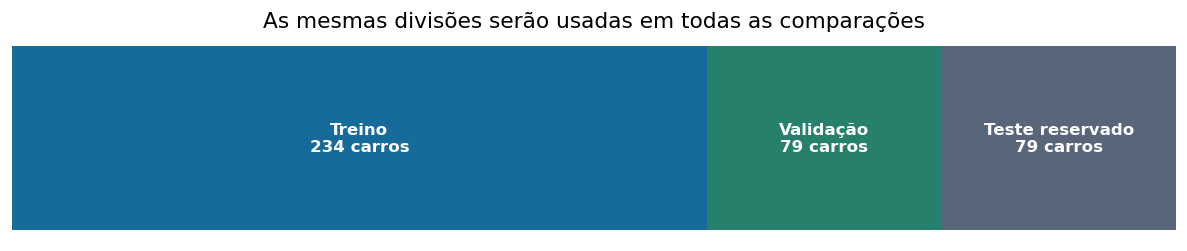

In [6]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=42
)
display(pd.DataFrame({
    "Conjunto": ["Treino", "Validação", "Teste reservado"],
    "Amostras": [len(y_train), len(y_val), len(y_test)],
}))
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

fig, ax = plt.subplots(figsize=(10, 2.2))
inicio = 0
for nome, n, cor in zip(["Treino", "Validação", "Teste reservado"],
                        [len(y_train), len(y_val), len(y_test)],
                        [AZUL, VERDE, "#596579"]):
    ax.barh(0, n, left=inicio, color=cor, height=0.55)
    ax.text(inicio + n / 2, 0, f"{nome}\n{n} carros", ha="center", va="center", color="white", weight="bold")
    inicio += n
ax.set_xlim(0, len(y))
ax.set_title("As mesmas divisões serão usadas em todas as comparações")
ax.axis("off")
plt.tight_layout()
plt.show()

### 3.1. Observar os dados de treino

Cada ponto no próximo gráfico é um carro. O eixo horizontal mostra o peso e o vertical, a eficiência.

**Antes de executar:** você espera que carros mais pesados façam mais ou menos quilômetros por litro?

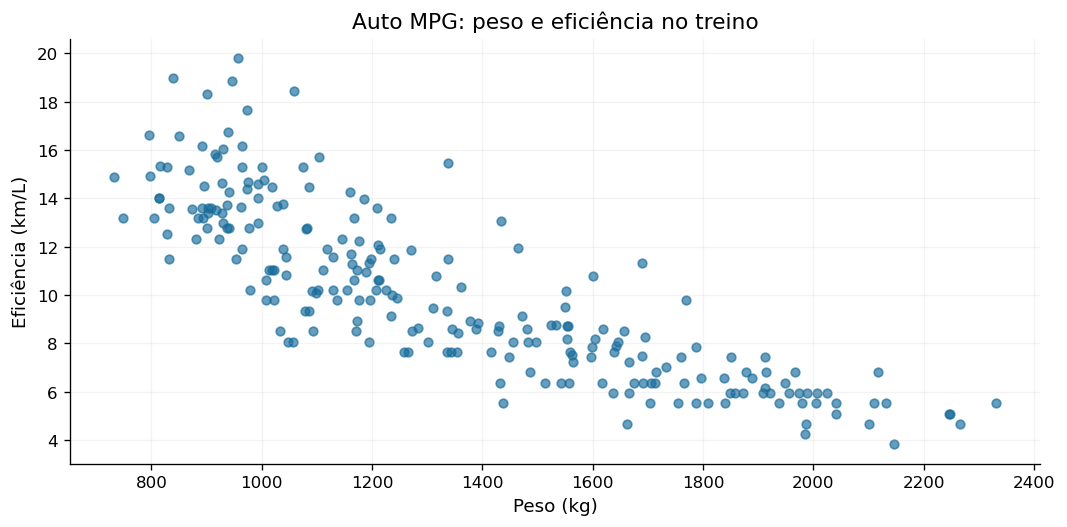

In [7]:
fig, ax = plt.subplots()
ax.scatter(X_train["peso_kg"], y_train, color=AZUL, alpha=0.65, s=27)
ax.set(title="Auto MPG: peso e eficiência no treino", xlabel="Peso (kg)", ylabel="Eficiência (km/L)")
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

## 4. Regressão linear simples: uma entrada, uma reta

Na regressão linear simples, usamos **uma variável de entrada** para prever um valor:

$$\hat{y} = b_0 + b_1x$$

| Símbolo | Significado |
|---|---|
| $x$ | Entrada: o peso do carro |
| $\hat{y}$ | Valor previsto: eficiência em km/L |
| $b_0$ | Intercepto: onde a reta encontra o eixo vertical quando $x=0$ |
| $b_1$ | Inclinação: quanto a previsão muda quando $x$ aumenta uma unidade |

Se $b_1$ é negativo, a reta desce. Se é positivo, a reta sobe.

**Exemplo apenas didático:** suponha a equação $\hat{y}=20-0{,}006x$. Para um carro de 1.000 kg:

$$\hat{y}=20-0{,}006\times 1000=14\ \text{km/L}$$

Agora deixaremos o `LinearRegression` encontrar os coeficientes usando os dados de treino, em vez de escolhê-los à mão.

In [8]:
modelo_simples = LinearRegression()
modelo_simples.fit(X_train[features_simples], y_train)

b0 = float(modelo_simples.intercept_)
b1 = float(modelo_simples.coef_[0])
print(f"Intercepto b0: {b0:.4f}")
print(f"Coeficiente b1: {b1:.6f} km/L por kg")
display(Math(r"\hat{y} = " + f"{b0:.4f} {b1:+.6f}" + r"\,x"))
print(f"Na reta ajustada, 100 kg a mais alteram a previsão em {100 * b1:.2f} km/L.")

Intercepto b0: 20.3448
Coeficiente b1: -0.007605 km/L por kg


<IPython.core.display.Math object>

Na reta ajustada, 100 kg a mais alteram a previsão em -0.76 km/L.


O coeficiente descreve uma **associação nos dados**, não prova uma relação de causa e efeito. O intercepto ajuda a posicionar a reta; não precisamos interpretar um carro de zero quilogramas como uma situação real.

### 4.1. Desenhar a reta ajustada

A reta resume a tendência, mas não precisa passar por todos os pontos. A distância vertical de cada ponto até ela será importante para avaliar os erros.

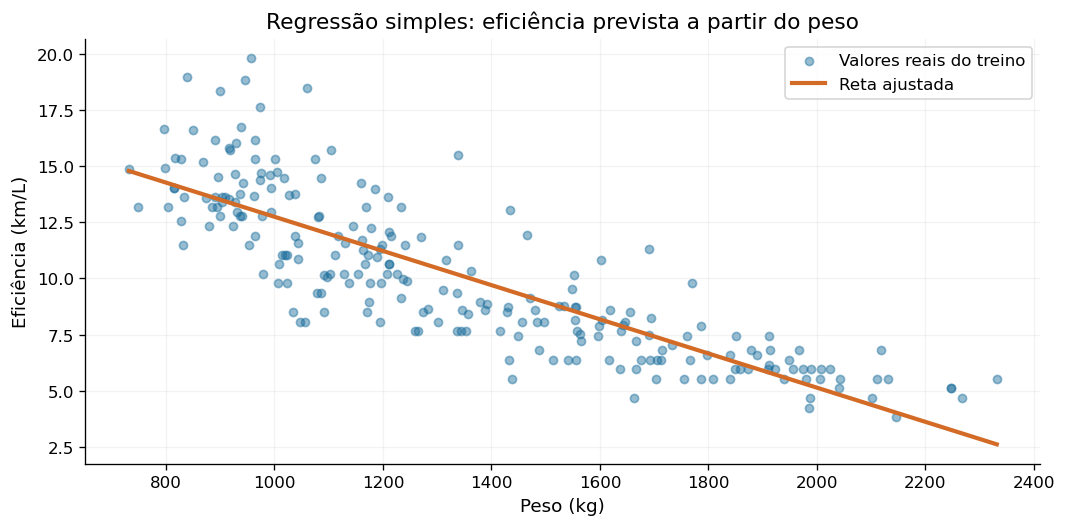

In [9]:
pesos_linha = pd.DataFrame({"peso_kg": np.linspace(X_train["peso_kg"].min(), X_train["peso_kg"].max(), 200)})
previsoes_linha = modelo_simples.predict(pesos_linha)

fig, ax = plt.subplots()
ax.scatter(X_train["peso_kg"], y_train, color=AZUL, alpha=0.45, s=24, label="Valores reais do treino")
ax.plot(pesos_linha["peso_kg"], previsoes_linha, color=LARANJA, linewidth=2.5, label="Reta ajustada")
ax.set(title="Regressão simples: eficiência prevista a partir do peso", xlabel="Peso (kg)", ylabel="Eficiência (km/L)")
ax.legend()
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

### 4.2. Como o modelo encontra a reta?

O ajuste por **mínimos quadrados** procura coeficientes que minimizem a soma dos erros elevados ao quadrado no treino:

$$\min_{b_0,b_1}\sum_{i=1}^{n}\left[y_i-(b_0+b_1x_i)\right]^2$$

$y_i$ é o valor real, $b_0+b_1x_i$ é a previsão e $n$ é a quantidade de exemplos de treino. Elevar ao quadrado impede que erros positivos e negativos se anulem e aumenta o peso dos erros grandes.

No caso simples, com variação em $x$, podemos calcular os coeficientes diretamente:

$$b_1=\frac{\sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y})}{\sum_{i=1}^{n}(x_i-\bar{x})^2}
\qquad
b_0=\bar{y}-b_1\bar{x}$$

$\bar{x}$ e $\bar{y}$ são as médias do treino. Não é necessário memorizar a fórmula: execute a conta abaixo e compare com o resultado da biblioteca.

In [10]:
x_treino = X_train["peso_kg"].to_numpy()
y_treino = y_train.to_numpy()
x_media, y_media = x_treino.mean(), y_treino.mean()
b1_manual = np.sum((x_treino - x_media) * (y_treino - y_media)) / np.sum((x_treino - x_media) ** 2)
b0_manual = y_media - b1_manual * x_media
display(pd.DataFrame({
    "Método": ["Conta com NumPy", "LinearRegression"],
    "b0": [b0_manual, b0], "b1": [b1_manual, b1],
}))
assert np.allclose([b0_manual, b1_manual], [b0, b1])

,Método,b0,b1
0,Conta com NumPy,20.344846,-0.007605
1,LinearRegression,20.344846,-0.007605


## 5. Regressão linear múltipla: várias entradas, um alvo

Um carro não se resume ao peso. Podemos incluir outras características:

$$\hat{y}=b_0+b_1x_1+b_2x_2+\cdots+b_px_p$$

Aqui, $p$ é o número de variáveis de entrada. **Múltipla significa várias entradas; continuamos prevendo apenas um alvo.**

Nesta aula:

$$\hat{y}=b_0+b_1\,\text{peso}+b_2\,\text{potência}+b_3\,\text{cilindrada}+b_4\,\text{anos desde 1970}$$

Cada coeficiente indica a alteração na previsão por uma unidade da respectiva entrada, **mantendo as outras constantes no modelo**. Não compare o tamanho dos coeficientes como se as variáveis tivessem a mesma unidade.

O critério de ajuste continua sendo minimizar a soma dos erros quadráticos. Usaremos as unidades originais convertidas para facilitar a leitura dos coeficientes; este ajuste linear por mínimos quadrados não exige padronização como o KNN baseado em distâncias.

In [11]:
modelo_multiplo = LinearRegression()
modelo_multiplo.fit(X_train[features_multiplas], y_train)
coeficientes = pd.DataFrame({
    "Entrada": features_multiplas,
    "Coeficiente": modelo_multiplo.coef_,
})
print(f"Intercepto: {modelo_multiplo.intercept_:.4f}")
display(coeficientes)

# Conferir a previsão de uma amostra por substituição na fórmula.
amostra = X_val[features_multiplas].iloc[[0]]
previsao_conta = modelo_multiplo.intercept_ + np.sum(amostra.iloc[0].to_numpy() * modelo_multiplo.coef_)
previsao_api = modelo_multiplo.predict(amostra)[0]
display(amostra.round(2))
print(f"Substituindo na fórmula: {previsao_conta:.2f} km/L")
print(f"Usando predict: {previsao_api:.2f} km/L")
assert np.isclose(previsao_conta, previsao_api)

Intercepto: 16.7898


,Entrada,Coeficiente
0,peso_kg,-0.006407
1,potencia_hp,-0.000837
2,cilindrada_l,0.006632
3,anos_desde_1970,0.322891


,peso_kg,potencia_hp,cilindrada_l,anos_desde_1970
234,1242.84,88.0,2.47,7


Substituindo na fórmula: 11.03 km/L
Usando predict: 11.03 km/L


### 5.1. Da reta ao plano

Com **uma entrada**, desenhamos uma reta em duas dimensões. Com **duas entradas**, desenhamos um plano em três dimensões. Com mais entradas, a mesma ideia se estende, mas já não conseguimos mostrar tudo em um gráfico 3D.

A ilustração abaixo ajusta um modelo com **peso e anos desde 1970**, apenas para visualizar o plano. O modelo múltiplo que estamos comparando continua sendo o de quatro entradas.

Os pontos são valores reais de treino; a superfície mostra as previsões. A distância vertical entre um ponto e o plano representa seu resíduo.

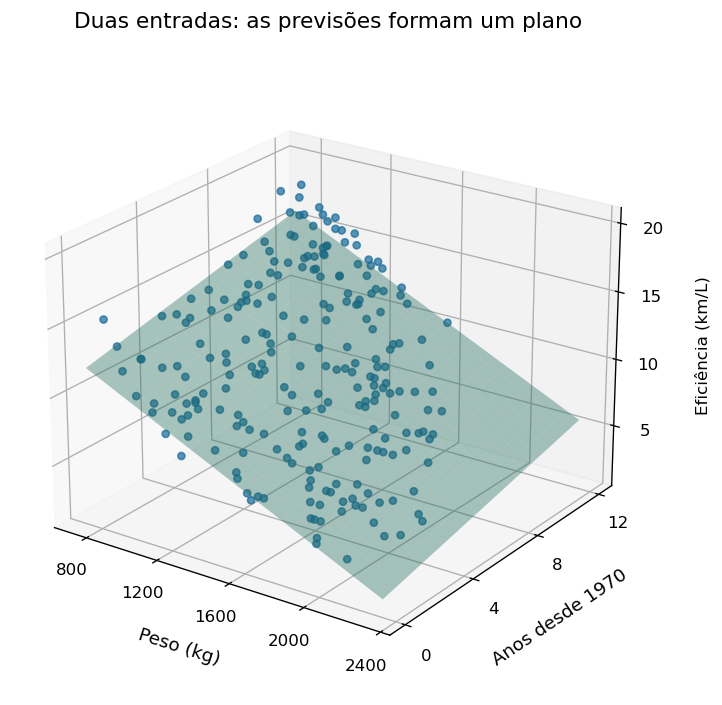

In [12]:
features_plano = ["peso_kg", "anos_desde_1970"]
modelo_plano = LinearRegression().fit(X_train[features_plano], y_train)
peso_grade, ano_grade = np.meshgrid(
    np.linspace(X_train["peso_kg"].min(), X_train["peso_kg"].max(), 25),
    np.linspace(0, 12, 25)
)
grade = pd.DataFrame({"peso_kg": peso_grade.ravel(), "anos_desde_1970": ano_grade.ravel()})
z_grade = modelo_plano.predict(grade).reshape(peso_grade.shape)

fig = plt.figure(figsize=(10, 6.2))
ax = fig.add_subplot(111, projection="3d")
ax.plot_surface(peso_grade, ano_grade, z_grade, color=VERDE, alpha=0.38, edgecolor="none")
ax.scatter(X_train["peso_kg"], X_train["anos_desde_1970"], y_train, color=AZUL, s=18, alpha=0.7)
ax.set_xlabel("Peso (kg)", labelpad=9)
ax.set_ylabel("Anos desde 1970", labelpad=10)
ax.set_zlabel("")
ax.text2D(1.08, 0.55, "Eficiência (km/L)", transform=ax.transAxes, rotation=90, va="center")
ax.set_xticks([800, 1200, 1600, 2000, 2400])
ax.set_yticks([0, 4, 8, 12])
ax.set_zticks([5, 10, 15, 20])
ax.set_title("Duas entradas: as previsões formam um plano", pad=20)
ax.view_init(elev=23, azim=-55)
fig.subplots_adjust(left=0.02, right=0.88, bottom=0.05, top=0.9)
plt.show()

## 6. Resíduo: a distância entre o real e o previsto

Para cada observação, definiremos:

$$e_i=y_i-\hat{y}_i$$

- **Resíduo positivo:** o valor real é maior; o modelo subestimou.
- **Resíduo negativo:** o valor real é menor; o modelo superestimou.
- **Resíduo zero:** a previsão coincidiu com o valor real.

Se um carro faz 10 km/L e o modelo prevê 12 km/L, o resíduo é $10-12=-2$ km/L. O erro absoluto é 2 km/L.

**Observe o gráfico:** os segmentos verticais ligam valores reais às previsões da reta. Quanto maior o segmento, maior o erro absoluto.

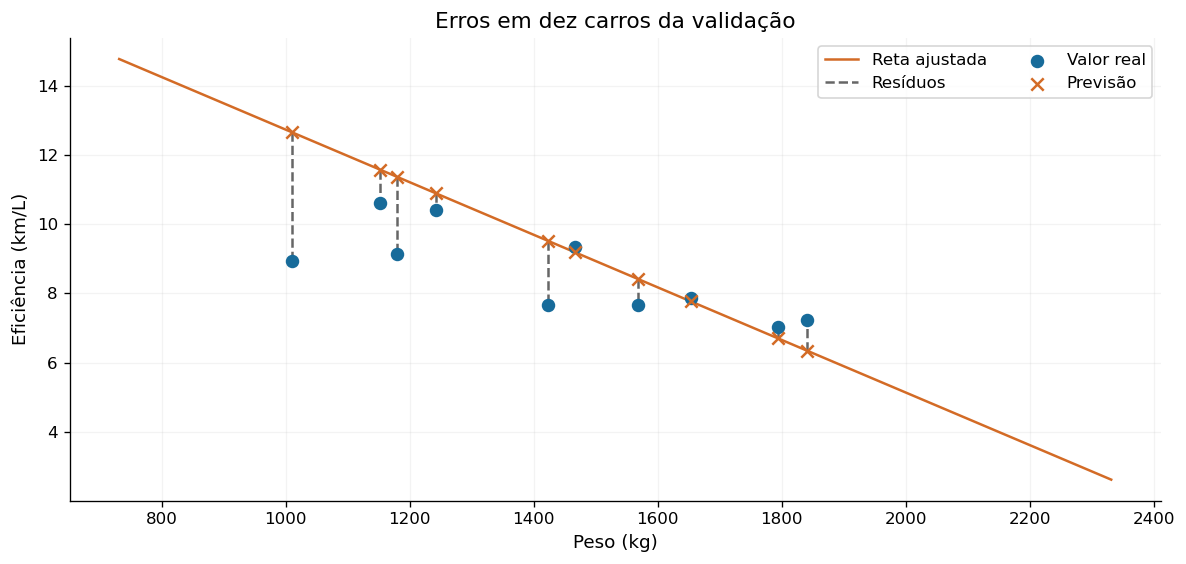

In [13]:
amostras_residuos = X_val[features_simples].iloc[:10].copy()
reais_residuos = y_val.iloc[:10].to_numpy()
prev_residuos = modelo_simples.predict(amostras_residuos)

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(pesos_linha["peso_kg"], previsoes_linha, color=LARANJA, label="Reta ajustada")
ax.vlines(amostras_residuos["peso_kg"], prev_residuos, reais_residuos, color="#666666", linestyles="--", label="Resíduos")
ax.scatter(amostras_residuos["peso_kg"], reais_residuos, color=AZUL, s=50, zorder=3, label="Valor real")
ax.scatter(amostras_residuos["peso_kg"], prev_residuos, color=LARANJA, marker="x", s=55, zorder=3, label="Previsão")
ax.set(title="Erros em dez carros da validação", xlabel="Peso (kg)", ylabel="Eficiência (km/L)")
ax.legend(ncol=2)
ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

### 6.1. Um exemplo pequeno para calcular à mão

Considere três carros com valores reais `[10, 12, 14]` e previsões `[9, 13, 16]`, todos em km/L. Usaremos esse mesmo exemplo para entender as quatro métricas.

**Antes de executar:** calcule os três resíduos. Depois obtenha o módulo e o quadrado de cada um.

In [14]:
y_exemplo = np.array([10.0, 12.0, 14.0])
pred_exemplo = np.array([9.0, 13.0, 16.0])
erros_exemplo = y_exemplo - pred_exemplo
display(pd.DataFrame({
    "Real": y_exemplo, "Previsto": pred_exemplo,
    "Resíduo": erros_exemplo,
    "Erro absoluto": np.abs(erros_exemplo),
    "Erro ao quadrado": erros_exemplo ** 2,
}))

,Real,Previsto,Resíduo,Erro absoluto,Erro ao quadrado
0,10.0,9.0,1.0,1.0,1.0
1,12.0,13.0,-1.0,1.0,1.0
2,14.0,16.0,-2.0,2.0,4.0


## 7. Métricas para avaliar as previsões

### 7.1. MAE: erro absoluto médio

$$\mathrm{MAE}=\frac{1}{n}\sum_{i=1}^{n}|y_i-\hat{y}_i|$$

Somamos os erros em módulo e dividimos pelo número de previsões:

$$\mathrm{MAE}=\frac{1+1+2}{3}\approx 1{,}33\ \text{km/L}$$

**Leitura:** neste exemplo, as previsões se afastam dos valores reais, em média, 1,33 km/L. Isso não significa que todas erram exatamente 1,33.

**Quanto menor, melhor.** A unidade é a mesma do alvo.

In [15]:
mae_manual = np.mean(np.abs(erros_exemplo))
print(f"Conta manual: {mae_manual:.4f} km/L")
print(f"mean_absolute_error: {mean_absolute_error(y_exemplo, pred_exemplo):.4f} km/L")

Conta manual: 1.3333 km/L
mean_absolute_error: 1.3333 km/L


### 7.2. MSE: erro quadrático médio

$$\mathrm{MSE}=\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2$$

$$\mathrm{MSE}=\frac{1^2+(-1)^2+(-2)^2}{3}=2\ (\text{km/L})^2$$

O quadrado dá mais peso aos erros grandes: um erro de 2 contribui com 4; um erro de 6 contribui com 36.

**Quanto menor, melhor.** A unidade fica ao quadrado. A regressão linear por mínimos quadrados minimiza a soma desses quadrados no treino; como $n$ é fixo, isso também minimiza o MSE de treino.

In [16]:
mse_manual = np.mean(erros_exemplo ** 2)
print(f"Conta manual: {mse_manual:.4f} (km/L)²")
print(f"mean_squared_error: {mean_squared_error(y_exemplo, pred_exemplo):.4f} (km/L)²")

Conta manual: 2.0000 (km/L)²
mean_squared_error: 2.0000 (km/L)²


### 7.3. RMSE: raiz do erro quadrático médio

$$\mathrm{RMSE}=\sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}=\sqrt{\mathrm{MSE}}$$

$$\mathrm{RMSE}=\sqrt{2}\approx 1{,}41\ \text{km/L}$$

A raiz devolve a métrica à unidade original do alvo. O RMSE continua sendo mais sensível a erros grandes do que o MAE.

**Quanto menor, melhor.** Use MAE para comunicar o desvio absoluto médio e RMSE quando também quiser dar mais peso a erros grandes. Não são percentuais.

In [17]:
rmse_manual = np.sqrt(mse_manual)
print(f"Conta manual: {rmse_manual:.4f} km/L")
print(f"Raiz do MSE da biblioteca: {np.sqrt(mean_squared_error(y_exemplo, pred_exemplo)):.4f} km/L")

Conta manual: 1.4142 km/L
Raiz do MSE da biblioteca: 1.4142 km/L


### 7.4. $R^2$: coeficiente de determinação

$$R^2=1-\frac{\sum_{i=1}^{n}(y_i-\hat{y}_i)^2}{\sum_{i=1}^{n}(y_i-\bar{y})^2}$$

O numerador mede o erro quadrático das previsões. O denominador mede o erro que teríamos usando a **média dos valores reais do conjunto avaliado** como previsão para todos.

No nosso exemplo, a média é 12:

$$R^2=1-\frac{6}{(10-12)^2+(12-12)^2+(14-12)^2}=1-\frac{6}{8}=0{,}25$$

O modelo reduziu em 25% o erro quadrático em relação a essa referência constante. **Isso não significa 25% de acertos.**

| Valor de $R^2$ | Interpretação, quando o alvo varia |
|---|---|
| $1$ | Previsões perfeitas |
| $0$ | Mesmo erro quadrático de prever a média do conjunto avaliado |
| Negativo | Erro quadrático maior que o dessa referência |

**Quanto maior, melhor.** $R^2$ não tem unidade e não é a acurácia da classificação. Em `LinearRegression`, o método `.score()` retorna $R^2$.

In [18]:
soma_erros_quadrados = np.sum(erros_exemplo ** 2)
soma_desvios_media = np.sum((y_exemplo - y_exemplo.mean()) ** 2)
r2_manual = 1 - soma_erros_quadrados / soma_desvios_media
print(f"Conta manual: {r2_manual:.4f}")
print(f"r2_score: {r2_score(y_exemplo, pred_exemplo):.4f}")

display(pd.DataFrame({
    "Previsões": ["Perfeitas: [10, 12, 14]", "Média: [12, 12, 12]", "Constante distante: [14, 14, 14]"],
    "R2": [r2_score(y_exemplo, y_exemplo),
           r2_score(y_exemplo, np.full(3, 12.0)),
           r2_score(y_exemplo, np.full(3, 14.0))],
}))
assert np.allclose([mae_manual, mse_manual, rmse_manual, r2_manual],
                   [4 / 3, 2, np.sqrt(2), 0.25])

Conta manual: 0.2500
r2_score: 0.2500


,Previsões,R2
0,"Perfeitas: [10, 12, 14]",1.0
1,"Média: [12, 12, 12]",0.0
2,"Constante distante: [14, 14, 14]",-1.5


### 7.5. Escolher a métrica antes de comparar

| Métrica | Melhor direção | Unidade nesta aula | Pergunta que ajuda a responder |
|---|---|---|---|
| MAE | Menor | km/L | Quanto erramos, em média, em valor absoluto? |
| MSE | Menor | (km/L)² | Qual é a média dos erros ao quadrado? |
| RMSE | Menor | km/L | Qual é o erro quadrático na unidade original? |
| R² | Maior | Sem unidade | Quanto melhoramos em relação à referência da média? |

**Critério desta aula:** escolher pelo **menor RMSE de validação**. As outras métricas ajudarão na interpretação. Não existe um MAE “bom” para qualquer problema: a unidade, a escala do alvo e a finalidade da previsão importam.

## 8. Comparar com uma referência simples

Antes de usar as características do carro, podemos prever a **média do treino para todos**. Essa é a nossa baseline.

O `DummyRegressor(strategy="mean")` aprende essa média usando apenas o treino. Sua média pode diferir da média da validação; por isso, seu R² na validação não precisa ser exatamente zero.

In [19]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)
print(f"Previsão constante da baseline: {float(y_train.mean()):.2f} km/L")

Previsão constante da baseline: 10.12 km/L


### 8.1. Calcular as quatro métricas para cada modelo

A função abaixo reúne as contas em um único lugar. Em seguida, aplicamos essa mesma avaliação aos mesmos carros de validação.

In [20]:
def avaliar_regressao(y_real, y_previsto):
    mse = mean_squared_error(y_real, y_previsto)
    return {
        "MAE": mean_absolute_error(y_real, y_previsto),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_real, y_previsto),
    }

,MAE,MSE,RMSE,R2
Modelo,,,,
Baseline,2.5332,8.8598,2.9765,-0.0135
Simples,1.3303,3.1112,1.7639,0.6441
Múltipla,0.9975,1.6982,1.3031,0.8057


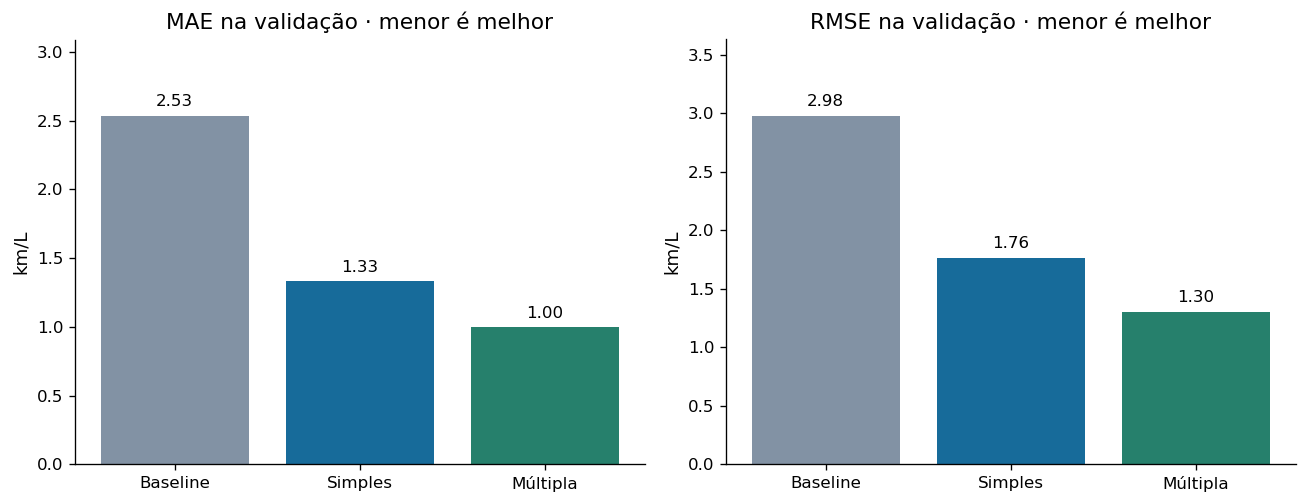

In [21]:
pred_baseline_val = baseline.predict(X_val)
pred_simples_val = modelo_simples.predict(X_val[features_simples])
pred_multiplo_val = modelo_multiplo.predict(X_val[features_multiplas])

comparacao_val = pd.DataFrame([
    {"Modelo": "Baseline", **avaliar_regressao(y_val, pred_baseline_val)},
    {"Modelo": "Simples", **avaliar_regressao(y_val, pred_simples_val)},
    {"Modelo": "Múltipla", **avaliar_regressao(y_val, pred_multiplo_val)},
]).set_index("Modelo")
display(comparacao_val.round(4))

fig, eixos = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, metrica in zip(eixos, ["MAE", "RMSE"]):
    barras = ax.bar(comparacao_val.index, comparacao_val[metrica], color=["#8292A4", AZUL, VERDE])
    ax.bar_label(barras, fmt="%.2f", padding=4)
    ax.set(title=f"{metrica} na validação · menor é melhor", ylabel="km/L")
    ax.set_ylim(0, comparacao_val[metrica].max() * 1.22)
plt.tight_layout()
plt.show()

Na execução de referência, o RMSE de validação cai de aproximadamente **1,76 km/L no modelo simples para 1,30 km/L no múltiplo**. As quatro entradas ajudam neste experimento.

Isso não cria uma regra de que mais entradas sempre produzem um modelo melhor. A escolha depende dos resultados nos exemplos que não participaram do ajuste.

**Responda:** qual dos modelos teve o menor MAE? Ele também teve o menor RMSE?

## 9. Entender os erros pelos gráficos

### 9.1. Valor real versus valor previsto

Na linha tracejada, o valor previsto é igual ao real. Pontos próximos dessa linha correspondem a previsões próximas do observado. Pontos acima indicam superestimação; abaixo, subestimação.

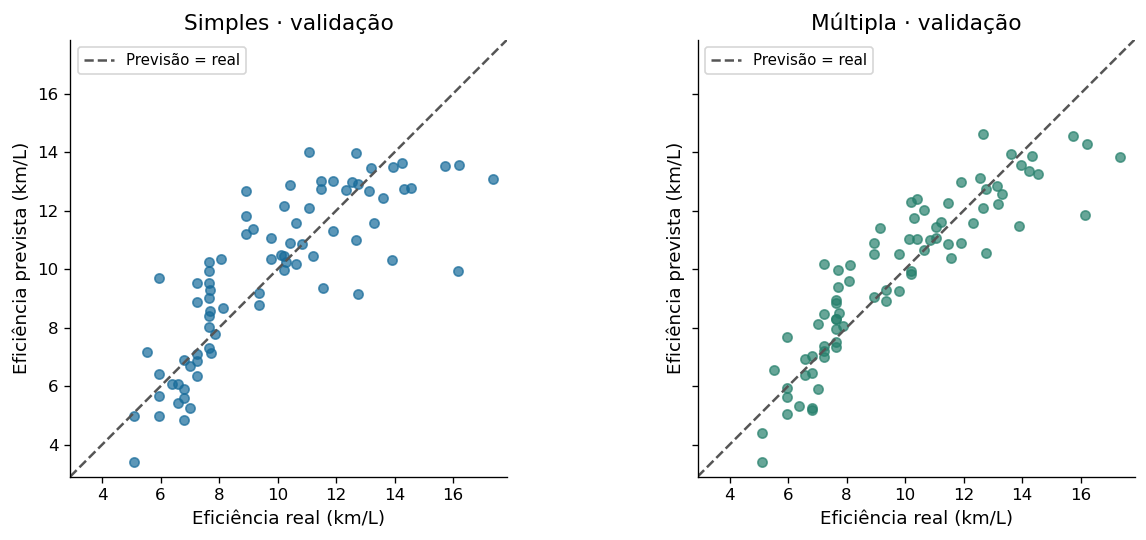

In [22]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.6), sharex=True, sharey=True)
limite_min = min(y_val.min(), pred_simples_val.min(), pred_multiplo_val.min()) - 0.5
limite_max = max(y_val.max(), pred_simples_val.max(), pred_multiplo_val.max()) + 0.5
for ax, nome, pred, cor in zip(eixos, ["Simples", "Múltipla"],
                               [pred_simples_val, pred_multiplo_val], [AZUL, VERDE]):
    ax.scatter(y_val, pred, color=cor, alpha=0.7, s=31)
    ax.plot([limite_min, limite_max], [limite_min, limite_max], "--", color="#555555", label="Previsão = real")
    ax.set(title=f"{nome} · validação", xlabel="Eficiência real (km/L)", ylabel="Eficiência prevista (km/L)",
           xlim=(limite_min, limite_max), ylim=(limite_min, limite_max))
    ax.set_aspect("equal", adjustable="box")
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

### 9.2. Resíduos versus valores previstos

Agora o eixo vertical mostra `real - previsto`. A linha zero representa erro zero.

- Pontos espalhados dos dois lados do zero, sem um desenho claro, são um sinal favorável.
- Uma curva nos resíduos sugere um padrão que o modelo não capturou.
- Um “funil” sugere que a dispersão dos erros muda conforme o valor previsto.
- Pontos muito afastados do zero merecem atenção, pois representam erros grandes.

Esse gráfico complementa as métricas: dois modelos podem ter erros médios próximos e errar de maneiras diferentes.

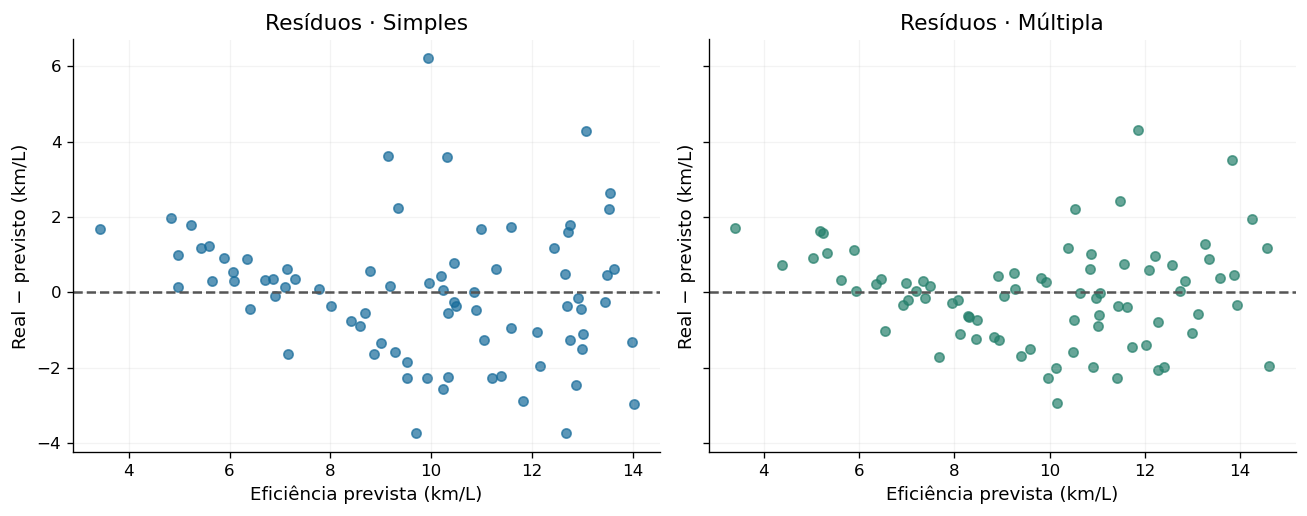

In [23]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, nome, pred, cor in zip(eixos, ["Simples", "Múltipla"],
                               [pred_simples_val, pred_multiplo_val], [AZUL, VERDE]):
    residuos = y_val.to_numpy() - pred
    ax.scatter(pred, residuos, color=cor, alpha=0.7, s=31)
    ax.axhline(0, linestyle="--", color="#555555")
    ax.set(title=f"Resíduos · {nome}", xlabel="Eficiência prevista (km/L)", ylabel="Real − previsto (km/L)")
    ax.grid(alpha=0.15)
plt.tight_layout()
plt.show()

## 10. Generalização, underfitting e overfitting

**Generalizar** é prever bem para exemplos que não participaram do ajuste. Por isso, vale comparar o erro no treino e na validação.

| Situação | Erro no treino | Erro na validação | Ideia central |
|---|---|---|---|
| Underfitting | Alto | Também alto | O modelo não representa bem o padrão |
| Ajuste adequado | Baixo | Baixo e relativamente próximo | O padrão aprendido se transfere |
| Overfitting | Muito baixo | Sensivelmente maior | O ajuste se prende a particularidades do treino |

Aqui estamos olhando **erro**: menor é melhor. Na aula de classificação, olhávamos acurácia: maior era melhor.

Uma diferença pequena entre treino e validação é normal. Acrescentar entradas não prova overfitting; precisamos observar o comportamento nos dois conjuntos.

In [24]:
erros_conjuntos = pd.DataFrame({
    "Modelo": ["Simples", "Múltipla"],
    "RMSE treino": [
        np.sqrt(mean_squared_error(y_train, modelo_simples.predict(X_train[features_simples]))),
        np.sqrt(mean_squared_error(y_train, modelo_multiplo.predict(X_train[features_multiplas]))),
    ],
    "RMSE validação": [comparacao_val.loc["Simples", "RMSE"], comparacao_val.loc["Múltipla", "RMSE"]],
})
display(erros_conjuntos.round(4))

,Modelo,RMSE treino,RMSE validação
0,Simples,1.8873,1.7639
1,Múltipla,1.5245,1.3031


### 10.1. Ilustração: quando uma reta é simples demais ou uma curva é flexível demais

O exemplo a seguir usa **dados simulados**, independentes dos carros. O padrão verdadeiro é uma curva suave. Compararemos uma reta, uma curva quadrática e uma curva muito flexível.

A linha cinza tracejada mostra o padrão usado para gerar os dados; os pontos incluem ruído. As três opções recebem o mesmo treino e a mesma validação. O objetivo é observar o efeito da flexibilidade, sem precisar estudar regressão polinomial em detalhes nesta aula.

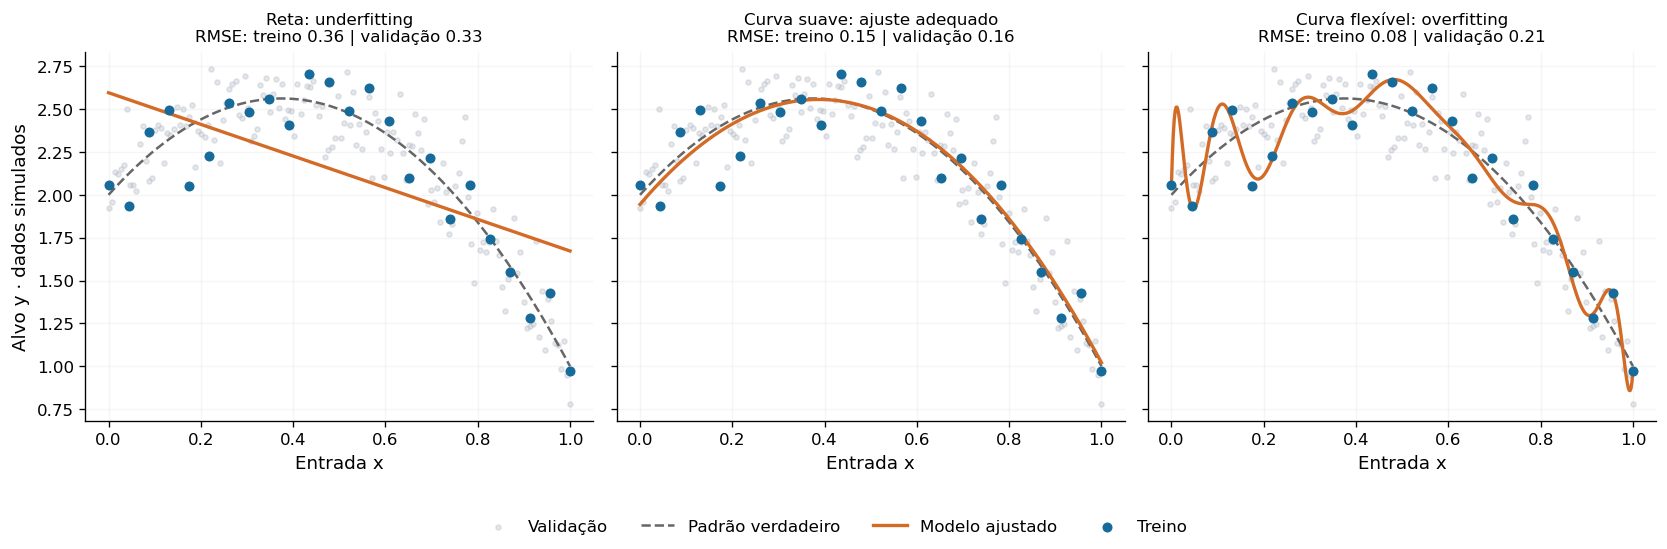

,Ajuste,RMSE treino,RMSE validação
0,Reta: underfitting,0.3615,0.3294
1,Curva suave: ajuste adequado,0.1469,0.1610
2,Curva flexível: overfitting,0.0797,0.2103


In [25]:
#@title Visualizar os três tipos de ajuste
from numpy.polynomial import Polynomial

rng = np.random.default_rng(42)
x_demo = np.linspace(0, 1, 24)
padrao = lambda x: 2 + 3 * x - 4 * x ** 2
y_demo = padrao(x_demo) + rng.normal(0, 0.18, len(x_demo))
x_demo_val = np.linspace(0, 1, 150)
y_demo_val = padrao(x_demo_val) + rng.normal(0, 0.18, len(x_demo_val))
x_desenho = np.linspace(0, 1, 500)

fig, eixos = plt.subplots(1, 3, figsize=(14, 4.6), sharex=True, sharey=True)
resultados_demo = []
for ax, grau, nome in zip(eixos, [1, 2, 15], ["Reta: underfitting", "Curva suave: ajuste adequado", "Curva flexível: overfitting"]):
    curva = Polynomial.fit(x_demo, y_demo, deg=grau)
    erro_treino = np.sqrt(mean_squared_error(y_demo, curva(x_demo)))
    erro_val = np.sqrt(mean_squared_error(y_demo_val, curva(x_demo_val)))
    resultados_demo.append({"Ajuste": nome, "RMSE treino": erro_treino, "RMSE validação": erro_val})
    ax.scatter(x_demo_val, y_demo_val, color="#B4BCC6", s=9, alpha=0.35, label="Validação")
    ax.plot(x_desenho, padrao(x_desenho), "--", color="#666666", label="Padrão verdadeiro")
    ax.plot(x_desenho, curva(x_desenho), color=LARANJA, linewidth=2, label="Modelo ajustado")
    ax.scatter(x_demo, y_demo, color=AZUL, s=25, zorder=4, label="Treino")
    ax.set_title(f"{nome}\nRMSE: treino {erro_treino:.2f} | validação {erro_val:.2f}", fontsize=10)
    ax.set_xlabel("Entrada x")
    ax.grid(alpha=0.12)
eixos[0].set_ylabel("Alvo y · dados simulados")
handles, labels = eixos[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0.1, 1, 1))
plt.show()
display(pd.DataFrame(resultados_demo).round(4))

**Observe os resultados:**

- A reta deixa de acompanhar a curvatura e tem erros maiores: **underfitting**.
- A curva suave acompanha o padrão e tem o menor erro de validação entre as três opções.
- A curva muito flexível reduz o erro de treino, mas piora a validação em relação à curva suave: **overfitting**.

**Pergunta:** por que escolher pelo menor erro de treino levaria à escolha errada neste exemplo?

## 11. Escolher e fazer a avaliação final

Voltamos à base de carros. O critério já está definido: **menor RMSE na validação**. Em um empate exato, manteremos a opção com menos entradas.

Depois da escolha, ajustaremos um novo modelo em **treino + validação** e faremos a avaliação final no teste. O teste não será usado para trocar as entradas ou escolher outro modelo.

In [26]:
# As opções já estão na ordem de simplicidade para resolver empates.
opcoes = pd.DataFrame({
    "Modelo": ["Simples", "Múltipla"],
    "RMSE": [comparacao_val.loc["Simples", "RMSE"], comparacao_val.loc["Múltipla", "RMSE"]],
    "Entradas": [len(features_simples), len(features_multiplas)],
})
escolha = opcoes.sort_values(["RMSE", "Entradas"]).iloc[0]["Modelo"]
features_finais = features_simples if escolha == "Simples" else features_multiplas
print("Escolha pela validação:", escolha)
print("Entradas:", features_finais)

modelo_final = LinearRegression().fit(X_dev[features_finais], y_dev)
pred_test = modelo_final.predict(X_test[features_finais])
baseline_final = DummyRegressor(strategy="mean").fit(X_dev, y_dev)

resultado_test = pd.DataFrame([
    {"Modelo": "Baseline final", **avaliar_regressao(y_test, baseline_final.predict(X_test))},
    {"Modelo": f"Final: {escolha}", **avaliar_regressao(y_test, pred_test)},
]).set_index("Modelo")
display(resultado_test.round(4))
print(f"score do LinearRegression no teste = R² = {modelo_final.score(X_test[features_finais], y_test):.4f}")

Escolha pela validação: Múltipla
Entradas: ['peso_kg', 'potencia_hp', 'cilindrada_l', 'anos_desde_1970']


,MAE,MSE,RMSE,R2
Modelo,,,,
Baseline final,2.5003,9.3302,3.0545,-0.0114
Final: Múltipla,1.0681,1.9229,1.3867,0.7916


score do LinearRegression no teste = R² = 0.7916


### 11.1. Interpretar a avaliação final

Na execução de referência, o modelo múltiplo escolhido apresenta **MAE de aproximadamente 1,07 km/L**, **RMSE de 1,39 km/L** e **R² de 0,79** no teste.

- **MAE:** o afastamento absoluto médio é de aproximadamente 1,07 km/L.
- **RMSE:** ao dar mais peso aos erros grandes e voltar à unidade original, obtemos 1,39 km/L.
- **R²:** o erro quadrático é cerca de 79% menor que o de prever a média dos valores reais desse teste. Não significa 79% de acertos.

Esses valores descrevem o desempenho nesta divisão da base histórica. Não garantem o mesmo resultado para qualquer carro moderno nem tornam segura a extrapolação para pesos fora da faixa observada.

,Real (km/L),Previsto (km/L),Resíduo (km/L)
79,11.05,11.01,0.04
276,9.18,11.14,-1.95
248,15.35,14.03,1.32
56,11.05,11.32,-0.27
393,11.48,12.52,-1.04
205,11.90,12.37,-0.47
43,5.53,3.25,2.27
235,11.05,12.40,-1.34
152,8.08,8.90,-0.83
117,12.33,12.29,0.04


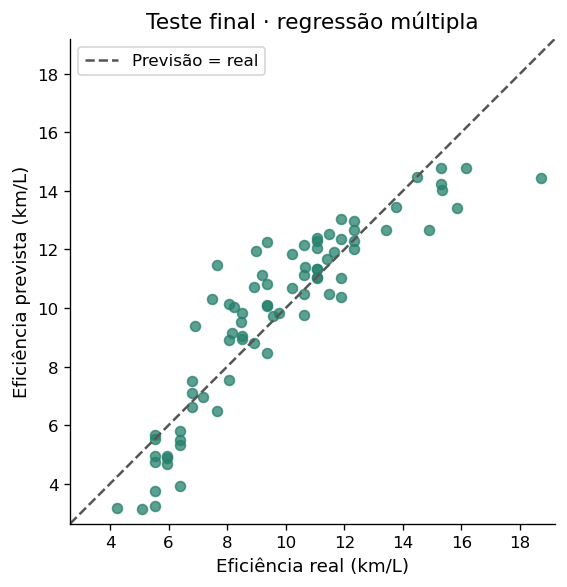

In [27]:
display(pd.DataFrame({
    "Real (km/L)": y_test,
    "Previsto (km/L)": pred_test,
    "Resíduo (km/L)": y_test.to_numpy() - pred_test,
}).head(10).round(2))

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_test, pred_test, color=VERDE, alpha=0.75, s=35)
limites = [min(y_test.min(), pred_test.min()) - 0.5, max(y_test.max(), pred_test.max()) + 0.5]
ax.plot(limites, limites, "--", color="#555555", label="Previsão = real")
ax.set(title=f"Teste final · regressão {escolha.lower()}", xlabel="Eficiência real (km/L)", ylabel="Eficiência prevista (km/L)",
       xlim=limites, ylim=limites)
ax.set_aspect("equal", adjustable="box")
ax.legend()
plt.tight_layout()
plt.show()

## 12. O que levar desta aula

| Ideia | O que lembrar |
|---|---|
| Regressão simples | Uma entrada para prever um valor |
| Regressão múltipla | Várias entradas para prever o mesmo alvo |
| Ajuste por mínimos quadrados | Minimizar a soma dos erros ao quadrado no treino |
| Resíduo | Valor real menos valor previsto |
| MAE, MSE e RMSE | Quanto menores, melhor; observe as unidades |
| R² | Quanto maior, melhor; não é acurácia e pode ser negativo |
| Generalização | Avaliar em exemplos fora do ajuste |
| Escolha do modelo | Usar a validação e reservar o teste para o final |

**Evite:** incluir o alvo em `X`; avaliar apenas no treino; escolher o modelo pelo teste; tratar R² como percentual de acertos; concluir que mais entradas sempre melhoram o resultado.

## 13. Exercícios para entregar até a próxima aula

**Aluno(a):** __________________________________  
**Turma:** __________________________________

Agora usaremos outra base real: **Palmer Penguins**. O objetivo será prever a **massa corporal dos pinguins, em gramas**, a partir de suas medidas. A base contém 344 registros; este notebook inclui as quatro colunas necessárias à atividade.

| Coluna | Significado |
|---|---|
| `flipper_length_mm` | Comprimento da nadadeira, em milímetros |
| `bill_length_mm` | Comprimento do bico, em milímetros |
| `bill_depth_mm` | Profundidade do bico, em milímetros |
| `body_mass_g` | Massa corporal, em gramas: o alvo |

**Modelos a comparar:**
- Simples: apenas `flipper_length_mm`.
- Múltiplo: `flipper_length_mm`, `bill_length_mm` e `bill_depth_mm`.
- Baseline: média do alvo no treino.

**Entrega individual:** este notebook com código, resultados, figuras e respostas preenchidos. Salve como `Aula9_NomeSobrenome.ipynb`. Use o prefixo `ex_` nas variáveis para não sobrescrever as etapas anteriores.

**Critério de escolha:** menor RMSE de validação; em empate exato, escolher o modelo com menos entradas. Os seis exercícios totalizam **10 pontos**.

In [28]:
#@title Carregar Palmer Penguins (dados incluídos)
pinguins_original_csv = """flipper_length_mm,bill_length_mm,bill_depth_mm,body_mass_g
181.0,39.1,18.7,3750.0
186.0,39.5,17.4,3800.0
195.0,40.3,18.0,3250.0
,,,
193.0,36.7,19.3,3450.0
190.0,39.3,20.6,3650.0
181.0,38.9,17.8,3625.0
195.0,39.2,19.6,4675.0
193.0,34.1,18.1,3475.0
190.0,42.0,20.2,4250.0
186.0,37.8,17.1,3300.0
180.0,37.8,17.3,3700.0
182.0,41.1,17.6,3200.0
191.0,38.6,21.2,3800.0
198.0,34.6,21.1,4400.0
185.0,36.6,17.8,3700.0
195.0,38.7,19.0,3450.0
197.0,42.5,20.7,4500.0
184.0,34.4,18.4,3325.0
194.0,46.0,21.5,4200.0
174.0,37.8,18.3,3400.0
180.0,37.7,18.7,3600.0
189.0,35.9,19.2,3800.0
185.0,38.2,18.1,3950.0
180.0,38.8,17.2,3800.0
187.0,35.3,18.9,3800.0
183.0,40.6,18.6,3550.0
187.0,40.5,17.9,3200.0
172.0,37.9,18.6,3150.0
180.0,40.5,18.9,3950.0
178.0,39.5,16.7,3250.0
178.0,37.2,18.1,3900.0
188.0,39.5,17.8,3300.0
184.0,40.9,18.9,3900.0
195.0,36.4,17.0,3325.0
196.0,39.2,21.1,4150.0
190.0,38.8,20.0,3950.0
180.0,42.2,18.5,3550.0
181.0,37.6,19.3,3300.0
184.0,39.8,19.1,4650.0
182.0,36.5,18.0,3150.0
195.0,40.8,18.4,3900.0
186.0,36.0,18.5,3100.0
196.0,44.1,19.7,4400.0
185.0,37.0,16.9,3000.0
190.0,39.6,18.8,4600.0
182.0,41.1,19.0,3425.0
179.0,37.5,18.9,2975.0
190.0,36.0,17.9,3450.0
191.0,42.3,21.2,4150.0
186.0,39.6,17.7,3500.0
188.0,40.1,18.9,4300.0
190.0,35.0,17.9,3450.0
200.0,42.0,19.5,4050.0
187.0,34.5,18.1,2900.0
191.0,41.4,18.6,3700.0
186.0,39.0,17.5,3550.0
193.0,40.6,18.8,3800.0
181.0,36.5,16.6,2850.0
194.0,37.6,19.1,3750.0
185.0,35.7,16.9,3150.0
195.0,41.3,21.1,4400.0
185.0,37.6,17.0,3600.0
192.0,41.1,18.2,4050.0
184.0,36.4,17.1,2850.0
192.0,41.6,18.0,3950.0
195.0,35.5,16.2,3350.0
188.0,41.1,19.1,4100.0
190.0,35.9,16.6,3050.0
198.0,41.8,19.4,4450.0
190.0,33.5,19.0,3600.0
190.0,39.7,18.4,3900.0
196.0,39.6,17.2,3550.0
197.0,45.8,18.9,4150.0
190.0,35.5,17.5,3700.0
195.0,42.8,18.5,4250.0
191.0,40.9,16.8,3700.0
184.0,37.2,19.4,3900.0
187.0,36.2,16.1,3550.0
195.0,42.1,19.1,4000.0
189.0,34.6,17.2,3200.0
196.0,42.9,17.6,4700.0
187.0,36.7,18.8,3800.0
193.0,35.1,19.4,4200.0
191.0,37.3,17.8,3350.0
194.0,41.3,20.3,3550.0
190.0,36.3,19.5,3800.0
189.0,36.9,18.6,3500.0
189.0,38.3,19.2,3950.0
190.0,38.9,18.8,3600.0
202.0,35.7,18.0,3550.0
205.0,41.1,18.1,4300.0
185.0,34.0,17.1,3400.0
186.0,39.6,18.1,4450.0
187.0,36.2,17.3,3300.0
208.0,40.8,18.9,4300.0
190.0,38.1,18.6,3700.0
196.0,40.3,18.5,4350.0
178.0,33.1,16.1,2900.0
192.0,43.2,18.5,4100.0
192.0,35.0,17.9,3725.0
203.0,41.0,20.0,4725.0
183.0,37.7,16.0,3075.0
190.0,37.8,20.0,4250.0
193.0,37.9,18.6,2925.0
184.0,39.7,18.9,3550.0
199.0,38.6,17.2,3750.0
190.0,38.2,20.0,3900.0
181.0,38.1,17.0,3175.0
197.0,43.2,19.0,4775.0
198.0,38.1,16.5,3825.0
191.0,45.6,20.3,4600.0
193.0,39.7,17.7,3200.0
197.0,42.2,19.5,4275.0
191.0,39.6,20.7,3900.0
196.0,42.7,18.3,4075.0
188.0,38.6,17.0,2900.0
199.0,37.3,20.5,3775.0
189.0,35.7,17.0,3350.0
189.0,41.1,18.6,3325.0
187.0,36.2,17.2,3150.0
198.0,37.7,19.8,3500.0
176.0,40.2,17.0,3450.0
202.0,41.4,18.5,3875.0
186.0,35.2,15.9,3050.0
199.0,40.6,19.0,4000.0
191.0,38.8,17.6,3275.0
195.0,41.5,18.3,4300.0
191.0,39.0,17.1,3050.0
210.0,44.1,18.0,4000.0
190.0,38.5,17.9,3325.0
197.0,43.1,19.2,3500.0
193.0,36.8,18.5,3500.0
199.0,37.5,18.5,4475.0
187.0,38.1,17.6,3425.0
190.0,41.1,17.5,3900.0
191.0,35.6,17.5,3175.0
200.0,40.2,20.1,3975.0
185.0,37.0,16.5,3400.0
193.0,39.7,17.9,4250.0
193.0,40.2,17.1,3400.0
187.0,40.6,17.2,3475.0
188.0,32.1,15.5,3050.0
190.0,40.7,17.0,3725.0
192.0,37.3,16.8,3000.0
185.0,39.0,18.7,3650.0
190.0,39.2,18.6,4250.0
184.0,36.6,18.4,3475.0
195.0,36.0,17.8,3450.0
193.0,37.8,18.1,3750.0
187.0,36.0,17.1,3700.0
201.0,41.5,18.5,4000.0
192.0,46.5,17.9,3500.0
196.0,50.0,19.5,3900.0
193.0,51.3,19.2,3650.0
188.0,45.4,18.7,3525.0
197.0,52.7,19.8,3725.0
198.0,45.2,17.8,3950.0
178.0,46.1,18.2,3250.0
197.0,51.3,18.2,3750.0
195.0,46.0,18.9,4150.0
198.0,51.3,19.9,3700.0
193.0,46.6,17.8,3800.0
194.0,51.7,20.3,3775.0
185.0,47.0,17.3,3700.0
201.0,52.0,18.1,4050.0
190.0,45.9,17.1,3575.0
201.0,50.5,19.6,4050.0
197.0,50.3,20.0,3300.0
181.0,58.0,17.8,3700.0
190.0,46.4,18.6,3450.0
195.0,49.2,18.2,4400.0
181.0,42.4,17.3,3600.0
191.0,48.5,17.5,3400.0
187.0,43.2,16.6,2900.0
193.0,50.6,19.4,3800.0
195.0,46.7,17.9,3300.0
197.0,52.0,19.0,4150.0
200.0,50.5,18.4,3400.0
200.0,49.5,19.0,3800.0
191.0,46.4,17.8,3700.0
205.0,52.8,20.0,4550.0
187.0,40.9,16.6,3200.0
201.0,54.2,20.8,4300.0
187.0,42.5,16.7,3350.0
203.0,51.0,18.8,4100.0
195.0,49.7,18.6,3600.0
199.0,47.5,16.8,3900.0
195.0,47.6,18.3,3850.0
210.0,52.0,20.7,4800.0
192.0,46.9,16.6,2700.0
205.0,53.5,19.9,4500.0
210.0,49.0,19.5,3950.0
187.0,46.2,17.5,3650.0
196.0,50.9,19.1,3550.0
196.0,45.5,17.0,3500.0
196.0,50.9,17.9,3675.0
201.0,50.8,18.5,4450.0
190.0,50.1,17.9,3400.0
212.0,49.0,19.6,4300.0
187.0,51.5,18.7,3250.0
198.0,49.8,17.3,3675.0
199.0,48.1,16.4,3325.0
201.0,51.4,19.0,3950.0
193.0,45.7,17.3,3600.0
203.0,50.7,19.7,4050.0
187.0,42.5,17.3,3350.0
197.0,52.2,18.8,3450.0
191.0,45.2,16.6,3250.0
203.0,49.3,19.9,4050.0
202.0,50.2,18.8,3800.0
194.0,45.6,19.4,3525.0
206.0,51.9,19.5,3950.0
189.0,46.8,16.5,3650.0
195.0,45.7,17.0,3650.0
207.0,55.8,19.8,4000.0
202.0,43.5,18.1,3400.0
193.0,49.6,18.2,3775.0
210.0,50.8,19.0,4100.0
198.0,50.2,18.7,3775.0
211.0,46.1,13.2,4500.0
230.0,50.0,16.3,5700.0
210.0,48.7,14.1,4450.0
218.0,50.0,15.2,5700.0
215.0,47.6,14.5,5400.0
210.0,46.5,13.5,4550.0
211.0,45.4,14.6,4800.0
219.0,46.7,15.3,5200.0
209.0,43.3,13.4,4400.0
215.0,46.8,15.4,5150.0
214.0,40.9,13.7,4650.0
216.0,49.0,16.1,5550.0
214.0,45.5,13.7,4650.0
213.0,48.4,14.6,5850.0
210.0,45.8,14.6,4200.0
217.0,49.3,15.7,5850.0
210.0,42.0,13.5,4150.0
221.0,49.2,15.2,6300.0
209.0,46.2,14.5,4800.0
222.0,48.7,15.1,5350.0
218.0,50.2,14.3,5700.0
215.0,45.1,14.5,5000.0
213.0,46.5,14.5,4400.0
215.0,46.3,15.8,5050.0
215.0,42.9,13.1,5000.0
215.0,46.1,15.1,5100.0
216.0,44.5,14.3,4100.0
215.0,47.8,15.0,5650.0
210.0,48.2,14.3,4600.0
220.0,50.0,15.3,5550.0
222.0,47.3,15.3,5250.0
209.0,42.8,14.2,4700.0
207.0,45.1,14.5,5050.0
230.0,59.6,17.0,6050.0
220.0,49.1,14.8,5150.0
220.0,48.4,16.3,5400.0
213.0,42.6,13.7,4950.0
219.0,44.4,17.3,5250.0
208.0,44.0,13.6,4350.0
208.0,48.7,15.7,5350.0
208.0,42.7,13.7,3950.0
225.0,49.6,16.0,5700.0
210.0,45.3,13.7,4300.0
216.0,49.6,15.0,4750.0
222.0,50.5,15.9,5550.0
217.0,43.6,13.9,4900.0
210.0,45.5,13.9,4200.0
225.0,50.5,15.9,5400.0
213.0,44.9,13.3,5100.0
215.0,45.2,15.8,5300.0
210.0,46.6,14.2,4850.0
220.0,48.5,14.1,5300.0
210.0,45.1,14.4,4400.0
225.0,50.1,15.0,5000.0
217.0,46.5,14.4,4900.0
220.0,45.0,15.4,5050.0
208.0,43.8,13.9,4300.0
220.0,45.5,15.0,5000.0
208.0,43.2,14.5,4450.0
224.0,50.4,15.3,5550.0
208.0,45.3,13.8,4200.0
221.0,46.2,14.9,5300.0
214.0,45.7,13.9,4400.0
231.0,54.3,15.7,5650.0
219.0,45.8,14.2,4700.0
230.0,49.8,16.8,5700.0
214.0,46.2,14.4,4650.0
229.0,49.5,16.2,5800.0
220.0,43.5,14.2,4700.0
223.0,50.7,15.0,5550.0
216.0,47.7,15.0,4750.0
221.0,46.4,15.6,5000.0
221.0,48.2,15.6,5100.0
217.0,46.5,14.8,5200.0
216.0,46.4,15.0,4700.0
230.0,48.6,16.0,5800.0
209.0,47.5,14.2,4600.0
220.0,51.1,16.3,6000.0
215.0,45.2,13.8,4750.0
223.0,45.2,16.4,5950.0
212.0,49.1,14.5,4625.0
221.0,52.5,15.6,5450.0
212.0,47.4,14.6,4725.0
224.0,50.0,15.9,5350.0
212.0,44.9,13.8,4750.0
228.0,50.8,17.3,5600.0
218.0,43.4,14.4,4600.0
218.0,51.3,14.2,5300.0
212.0,47.5,14.0,4875.0
230.0,52.1,17.0,5550.0
218.0,47.5,15.0,4950.0
228.0,52.2,17.1,5400.0
212.0,45.5,14.5,4750.0
224.0,49.5,16.1,5650.0
214.0,44.5,14.7,4850.0
226.0,50.8,15.7,5200.0
216.0,49.4,15.8,4925.0
222.0,46.9,14.6,4875.0
203.0,48.4,14.4,4625.0
225.0,51.1,16.5,5250.0
219.0,48.5,15.0,4850.0
228.0,55.9,17.0,5600.0
215.0,47.2,15.5,4975.0
228.0,49.1,15.0,5500.0
216.0,47.3,13.8,4725.0
215.0,46.8,16.1,5500.0
210.0,41.7,14.7,4700.0
219.0,53.4,15.8,5500.0
208.0,43.3,14.0,4575.0
209.0,48.1,15.1,5500.0
216.0,50.5,15.2,5000.0
229.0,49.8,15.9,5950.0
213.0,43.5,15.2,4650.0
230.0,51.5,16.3,5500.0
217.0,46.2,14.1,4375.0
230.0,55.1,16.0,5850.0
217.0,44.5,15.7,4875.0
222.0,48.8,16.2,6000.0
214.0,47.2,13.7,4925.0
,,,
215.0,46.8,14.3,4850.0
222.0,50.4,15.7,5750.0
212.0,45.2,14.8,5200.0
213.0,49.9,16.1,5400.0
"""
pinguins_original = pd.read_csv(StringIO(pinguins_original_csv))
print("Base carregada:", pinguins_original.shape)

Base carregada: (344, 4)


### Exercício 1 · Preparar os dados (1,0 ponto)

Mostre as primeiras linhas, conte os valores ausentes e remova as linhas incompletas nas quatro colunas fornecidas. Crie `ex_X` com as três entradas e `ex_y` com o alvo. Informe quantas linhas permaneceram.

Explique por que prever `body_mass_g` é um problema de regressão e por que essa coluna não pode entrar em `ex_X`.

In [29]:
# Sua solução do exercício 1.
# Use pinguins_original, .head(), .isna().sum() e .dropna().

**Resposta do exercício 1:** escreva aqui.

### Exercício 2 · Separar e visualizar (1,5 ponto)

1. Reserve 20% para teste com `random_state=7`.
2. Do conjunto restante, reserve 25% para validação, também com `random_state=7`.
3. Mostre o tamanho dos três conjuntos.
4. Faça um gráfico de dispersão entre comprimento da nadadeira e massa **usando o treino**.

Use `ex_X_dev`, `ex_X_train`, `ex_X_val`, `ex_X_test` e os nomes correspondentes para `y`. Descreva a tendência do gráfico em duas frases.

In [30]:
# Sua solução do exercício 2.
# Não use stratify diretamente no alvo contínuo.

**Resposta do exercício 2:** escreva aqui.

### Exercício 3 · Ajustar os modelos (2,0 pontos)

Ajuste a baseline, a regressão simples e a múltipla usando apenas o treino.

- Mostre o intercepto e o coeficiente da regressão simples.
- Escreva sua equação e interprete o coeficiente com as unidades.
- Mostre a tabela de coeficientes da regressão múltipla.
- Desenhe a reta simples sobre os pontos de treino.

**Dica:** use colchetes duplos, como `ex_X_train[["flipper_length_mm"]]`, para manter a entrada como tabela.

In [31]:
# Sua solução do exercício 3.

**Equação e interpretação do exercício 3:** escreva aqui.

### Exercício 4 · Comparar na validação (2,0 pontos)

Calcule MAE, MSE, RMSE e R² dos três modelos na validação e apresente uma tabela. Compare também o RMSE de treino dos dois modelos lineares.

Escolha entre a regressão simples e a múltipla pelo critério definido. Responda:
1. Aumentar a quantidade de entradas melhorou o RMSE de validação?
2. Se MAE e RMSE favorecerem modelos diferentes, qual deles você escolherá nesta atividade? Por quê?
3. Um R² de 0,80 significa 80% de previsões corretas?

Você pode reutilizar a função `avaliar_regressao`. Não calcule o desempenho de teste ainda.

In [32]:
# Sua solução do exercício 4.

**Escolha e respostas do exercício 4:** escreva aqui.

### Exercício 5 · Testar e analisar os erros (2,0 pontos)

Após fixar a escolha:
1. Ajuste novamente o modelo escolhido em treino + validação.
2. Calcule as quatro métricas no teste.
3. Faça os gráficos **real versus previsto** e **resíduos versus previsto**, com unidades e linhas de referência.
4. Escreva uma conclusão de 4 a 6 linhas com o modelo escolhido, o significado do MAE e uma limitação do experimento.

Não mude a escolha depois de consultar o teste.

In [33]:
# Sua solução do exercício 5.

**Conclusão do exercício 5:** escreva aqui.

### Exercício 6 · Calcular e interpretar (1,5 ponto)

Para quatro observações, considere:

| Observação | Real | Previsto |
|---|---:|---:|
| 1 | 10 | 9 |
| 2 | 12 | 13 |
| 3 | 14 | 12 |
| 4 | 16 | 18 |

Calcule os resíduos, MAE, MSE, RMSE e $R^2$. Mostre as contas em Markdown e confira os resultados com Python. Explique por que a média simples dos resíduos pode esconder erros.

In [34]:
# Conferência dos cálculos do exercício 6.

**Contas e resposta do exercício 6:** escreva aqui.

### Antes de entregar

- [ ] Preenchi nome e turma.
- [ ] Executei o notebook na ordem, sem erros.
- [ ] Entreguei as tabelas, as figuras e as interpretações.
- [ ] Usei a validação para escolher e o teste apenas no final.
- [ ] Mantive as unidades e não confundi R² com acurácia.
- [ ] Salvei o `.ipynb` com os resultados visíveis.

## Referências e origem dos dados

- **Quinlan, R. (1993). Auto MPG [Dataset].** UCI Machine Learning Repository. [DOI: 10.24432/C5859H](https://doi.org/10.24432/C5859H). Licença [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Cópia CSV obtida no [repositório de dados do Seaborn](https://github.com/mwaskom/seaborn-data/blob/master/mpg.csv). Adaptações nesta aula: seleção de cinco colunas, retirada de seis linhas incompletas, conversões de unidades e ano relativo a 1970.
- **Palmer Penguins:** dados de medições disponibilizados por Kristen Gorman e Palmer Station LTER; organização no pacote por Allison Horst, Alison Hill e Kristen Gorman. [Documentação e origem](https://allisonhorst.github.io/palmerpenguins/). Recorte de quatro medidas numéricas da [cópia CSV do Seaborn](https://github.com/mwaskom/seaborn-data/blob/master/penguins.csv). Valores ausentes preservados no carregamento para tratamento na atividade.
- [scikit-learn: LinearRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html).
- [scikit-learn: métricas de regressão](https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics).
- [scikit-learn: R²](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.r2_score.html).

As figuras são geradas pelo código e ficam incluídas nas saídas. A demonstração de underfitting e overfitting usa dados simulados, identificados na seção correspondente. As versões das bibliotecas aparecem no início do notebook.